# BÀI TẬP LỚN MÔN HỌC MÁY (MACHINE LEARNING)
## BÀI 1: PIPELINE HỌC MÁY VỚI DỮ LIỆU DẠNG BẢNG (TABULAR DATA)
### NOTEBOOK 02: PIPELINE TIỀN XỬ LÝ DỮ LIỆU (DATA PREPROCESSING PIPELINE)

- **Khoa:** Khoa Khoa học và Kỹ thuật Máy tính (CSE)
- **Trường:** Đại học Bách Khoa, ĐHQG-HCM
- **Bộ môn / Môn học:** Học máy (CO3011 / CO3013)
- **Tập dữ liệu:** [HR Analytics: Job Change of Data Scientists (aug_train.csv)](https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists)
- **Nhóm thực hiện:** Nhóm 3

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Puuffiiii/261-ML-Assignment-G3/blob/feature/preprocessing/notebooks/02_preprocessing_pipeline.ipynb)

---

### Mục tiêu của Notebook:
Notebook này hiện thực toàn bộ quy trình **Tiền xử lý dữ liệu (Preprocessing Pipeline)** bám sát Mục 4.1 và Mục 5 của đề bài PDF:
1. **Làm sạch & Phân tầng Train/Test (Stratified Split 80/20):** Tuyệt đối chống rò rỉ thông tin (Data Leakage).
2. **Xử lý khuyết thiếu bám sát EDA (MNAR Treatment):** Khắc phục cơ chế khuyết không ngẫu nhiên ở `company_size` và `company_type` bằng nhãn `'Unknown'` và `MissingIndicator`.
3. **Mã hóa đặc trưng (Categorical Encoding):** Ánh xạ thứ bậc (Ordinal Mapping) cho biến thứ bậc và One-Hot Encoding cho biến danh nghĩa.
4. **Thử nghiệm các cấu hình chuẩn hóa (Feature Scaling):** So sánh `StandardScaler` và `MinMaxScaler(feature_range=(0, 1) & (-1, 1))`.
5. **Thử nghiệm giảm chiều (PCA):** Khảo sát các mức phương sai tích lũy 90% và 95% theo yêu cầu đề bài.
6. **Lưu trữ đặc trưng chuẩn hóa ra file `.npy`:** Xuất vào thư mục `features/` để sẵn sàng cho pha huấn luyện mô hình.


## 0. Cấu hình môi trường và Nạp dữ liệu
Hệ thống tự động nhận diện và cấu hình tương thích cả trên Google Colab và máy cục bộ (Local).


In [1]:
# ==============================================================================
# 0. CẤU HÌNH MÔI TRƯỜNG TỰ ĐỘNG (GOOGLE COLAB & LOCAL)
# ==============================================================================
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách hiển thị học thuật
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#444444'
plt.rcParams['axes.linewidth'] = 0.8

# Nhận diện Google Colab
if "google.colab" in sys.modules:
    REPO_NAME = "261-ML-Assignment-G3"
    REPO_URL = "https://github.com/Puuffiiii/261-ML-Assignment-G3.git"
    BRANCH = "feature/preprocessing"
    if not os.path.exists(REPO_NAME):
        os.system(f"git clone -b {BRANCH} {REPO_URL}")
    repo_path = os.path.abspath(REPO_NAME)
    if repo_path not in sys.path:
        sys.path.insert(0, repo_path)
    notebooks_dir = os.path.join(repo_path, "notebooks")
    if os.path.exists(notebooks_dir):
        os.chdir(notebooks_dir)
    print(f"-> Đã cấu hình Google Colab. Thư mục làm việc: {os.getcwd()}")
else:
    project_root = os.path.abspath("..") if os.path.exists("../modules") else os.path.abspath(".")
    if project_root not in sys.path:
        sys.path.insert(0, project_root)

# Import module tiền xử lý độc lập từ modules/
from modules.preprocessing import (
    TabularPreprocessor,
    load_raw_dataset,
    split_train_test,
    save_processed_features,
    load_processed_features,
    ORDINAL_MAPPINGS,
    NUMERICAL_COLS,
    ORDINAL_COLS,
    NOMINAL_COLS,
    DROP_COLS,
    MNAR_COLS,
    TARGET_COL
)

# Nạp dữ liệu thô
DATA_PATH = "../data/aug_train.csv" if os.path.exists("../data/aug_train.csv") else "data/aug_train.csv"
df_raw = load_raw_dataset(DATA_PATH)
print(f"-> Nạp thành công tập dữ liệu: {df_raw.shape[0]:,} dòng và {df_raw.shape[1]} cột")
df_raw.head(3)


-> Nạp thành công tập dữ liệu: 19,158 dòng và 14 cột


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0


## 1. Loại bỏ đặc trưng thừa & Chia tách tập Train/Test (Chống Data Leakage)

Dựa trên phân tích EDA:
* `enrollee_id`: ID ngẫu nhiên, không mang giá trị dự báo.
* `city`: Có quan hệ 1-1 với `city_development_index`. Việc giữ lại `city` làm bùng nổ 123 cột one-hot không cần thiết. Do đó cột này được loại bỏ.
* **Nguyên tắc chống rò rỉ dữ liệu (Data Leakage):** Việc chia tách Train (80%) và Test (20%) phải được thực hiện **trước bất kỳ thao tác fit thống kê nào** (mean/median/mode/scaling/PCA).
* **Phân tầng (Stratified Split):** Do biến mục tiêu mất cân bằng (~24.9% nhãn 1), chia phân tầng đảm bảo tỷ lệ nhãn ở Train và Test đồng nhất.


In [2]:
# ==============================================================================
# 1. PHÂN TẦNG TẬP DỮ LIỆU TRAIN / TEST
# ==============================================================================
RANDOM_STATE = 42

X_train_raw, X_test_raw, y_train, y_test = split_train_test(
    df_raw,
    test_size=0.2,
    random_state=RANDOM_STATE,
    drop_unnecessary=True
)

print(f"Tập huấn luyện (Train set): {X_train_raw.shape[0]:,} dòng, {X_train_raw.shape[1]} đặc trưng")
print(f"Tập kiểm tra   (Test set) : {X_test_raw.shape[0]:,} dòng, {X_test_raw.shape[1]} đặc trưng")

# Kiểm chứng tỷ lệ nhãn mục tiêu sau khi phân tầng
dist_summary = pd.DataFrame({
    'Train Count': y_train.value_counts().sort_index(),
    'Train Pct (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Test Count': y_test.value_counts().sort_index(),
    'Test Pct (%)': (y_test.value_counts(normalize=True).sort_index() * 100).round(2)
})
dist_summary.index = ['Class 0 (Không đổi việc)', 'Class 1 (Muốn đổi việc)']
dist_summary


Tập huấn luyện (Train set): 15,326 dòng, 11 đặc trưng
Tập kiểm tra   (Test set) : 3,832 dòng, 11 đặc trưng


,Train Count,Train Pct (%),Test Count,Test Pct (%)
Class 0 (Không đổi việc),11504,75.06,2877,75.08
Class 1 (Muốn đổi việc),3822,24.94,955,24.92


## 2. Chiến lược xử lý Khuyết thiếu & Mã hóa phân loại (Encoding)

1. **MNAR (Missing Not At Random):**
   * Trong EDA, những ứng viên để trống `company_size` và `company_type` có tỷ lệ muốn nhảy việc cao đột biến (~38% – 40% so với ~18% ở nhóm có điền).
   * Giải pháp: Điền giá trị `'Unknown'` thành một nhóm riêng cho biến phân loại, đồng thời bổ sung cờ nhị phân `company_size_isna` và `company_type_isna` để mô hình nắm bắt thông tin giá trị khuyết này.
2. **Biến thứ bậc (Ordinal Features):**
   * `education_level`: Primary School (0) < High School (1) < Graduate (2) < Masters (3) < Phd (4).
   * `company_size`: <10 (0) < 10/49 (1) < 50-99 (2) < ... < 10000+ (7).
   * `experience`: <1 (0), 1 (1) ... 20 (20), >20 (21).
   * `last_new_job`: never (0) < 1 (1) < 2 (2) < 3 (3) < 4 (4) < >4 (5).
3. **Biến danh nghĩa (Nominal Features):**
   * Sử dụng `OneHotEncoder` cho `gender`, `relevent_experience`, `enrolled_university`, `major_discipline`, `company_type`.


In [3]:
# Kiểm tra các bảng ánh xạ thứ bậc đã định nghĩa trong module
print("--- CẤU TRÚC ÁNH XẠ THỨ BẬC (ORDINAL MAPPINGS) ---")
for col_name, mapping in ORDINAL_MAPPINGS.items():
    print(f"\n[Thuộc tính: {col_name}]")
    for k, v in list(mapping.items())[:6]:
        print(f"   '{k}' -> {v}")
    if len(mapping) > 6:
        print(f"   ... ({len(mapping)} mức bậc tất cả)")


--- CẤU TRÚC ÁNH XẠ THỨ BẬC (ORDINAL MAPPINGS) ---

[Thuộc tính: education_level]
   'Primary School' -> 0
   'High School' -> 1
   'Graduate' -> 2
   'Masters' -> 3
   'Phd' -> 4

[Thuộc tính: company_size]
   '<10' -> 0
   '10/49' -> 1
   '50-99' -> 2
   '100-500' -> 3
   '500-999' -> 4
   '1000-4999' -> 5
   ... (8 mức bậc tất cả)

[Thuộc tính: experience]
   '<1' -> 0
   '1' -> 1
   '2' -> 2
   '3' -> 3
   '4' -> 4
   '5' -> 5
   ... (22 mức bậc tất cả)

[Thuộc tính: last_new_job]
   'never' -> 0
   '1' -> 1
   '2' -> 2
   '3' -> 3
   '4' -> 4
   '>4' -> 5


## 3. Thử nghiệm các kỹ thuật Chuẩn hóa (Feature Scaling)

Theo yêu cầu Mục 4.1 đề bài PDF:
> *"Scaling: có thể lựa chọn MinMaxScaler hoặc StandardScaler; nếu chọn MinMaxScaler, sinh viên cần cấu hình feature_range."*

Ta tiến hành thử nghiệm và chuẩn bị 3 cấu hình Scaling:
* **Cấu hình 1:** `StandardScaler` (Chuẩn hóa Z-score: mean = 0, std = 1) — Phù hợp nhất với Logistic Regression, SVM, PCA.
* **Cấu hình 2:** `MinMaxScaler` với `feature_range=(0, 1)` — Đưa toàn bộ đặc trưng về khoảng [0, 1].
* **Cấu hình 3:** `MinMaxScaler` với `feature_range=(-1, 1)` — Đưa toàn bộ đặc trưng về khoảng [-1, 1], phù hợp cho mạng MLP sử dụng hàm kích hoạt tanh.


In [4]:
# ==============================================================================
# 3. FIT VÀ BIẾN ĐỔI CÁC CẤU HÌNH SCALING (FIT CHỈ TRÊN TRAIN)
# ==============================================================================
# Cấu hình 1: StandardScaler
preprocessor_std = TabularPreprocessor(scaling='standard', random_state=RANDOM_STATE)
X_train_std = preprocessor_std.fit_transform(X_train_raw)
X_test_std = preprocessor_std.transform(X_test_raw)

# Cấu hình 2: MinMaxScaler (0, 1)
preprocessor_minmax = TabularPreprocessor(scaling='minmax', feature_range=(0, 1), random_state=RANDOM_STATE)
X_train_minmax = preprocessor_minmax.fit_transform(X_train_raw)
X_test_minmax = preprocessor_minmax.transform(X_test_raw)

# Cấu hình 3: MinMaxScaler (-1, 1)
preprocessor_minmax_neg1_1 = TabularPreprocessor(scaling='minmax', feature_range=(-1, 1), random_state=RANDOM_STATE)
X_train_minmax_neg1_1 = preprocessor_minmax_neg1_1.fit_transform(X_train_raw)
X_test_minmax_neg1_1 = preprocessor_minmax_neg1_1.transform(X_test_raw)

feature_names = preprocessor_std.get_feature_names_out()
print(f"-> Số chiều ma trận đặc trưng sau tiền xử lý (chưa PCA): {X_train_std.shape[1]} cột")
print(f"-> Danh sách các cột đặc trưng tạo thành ({len(feature_names)} cột):")
for idx, name in enumerate(feature_names, 1):
    print(f"   {idx:2d}. {name}")


-> Số chiều ma trận đặc trưng sau tiền xử lý (chưa PCA): 32 cột
-> Danh sách các cột đặc trưng tạo thành (32 cột):
    1. city_development_index
    2. training_hours
    3. education_level
    4. company_size
    5. experience
    6. last_new_job
    7. company_size_isna
    8. company_type_isna
    9. gender_Female
   10. gender_Male
   11. gender_Other
   12. gender_Unknown
   13. relevent_experience_Has relevent experience
   14. relevent_experience_No relevent experience
   15. enrolled_university_Full time course
   16. enrolled_university_Part time course
   17. enrolled_university_Unknown
   18. enrolled_university_no_enrollment
   19. major_discipline_Arts
   20. major_discipline_Business Degree
   21. major_discipline_Humanities
   22. major_discipline_No Major
   23. major_discipline_Other
   24. major_discipline_STEM
   25. major_discipline_Unknown
   26. company_type_Early Stage Startup
   27. company_type_Funded Startup
   28. company_type_NGO
   29. company_type_Other
  

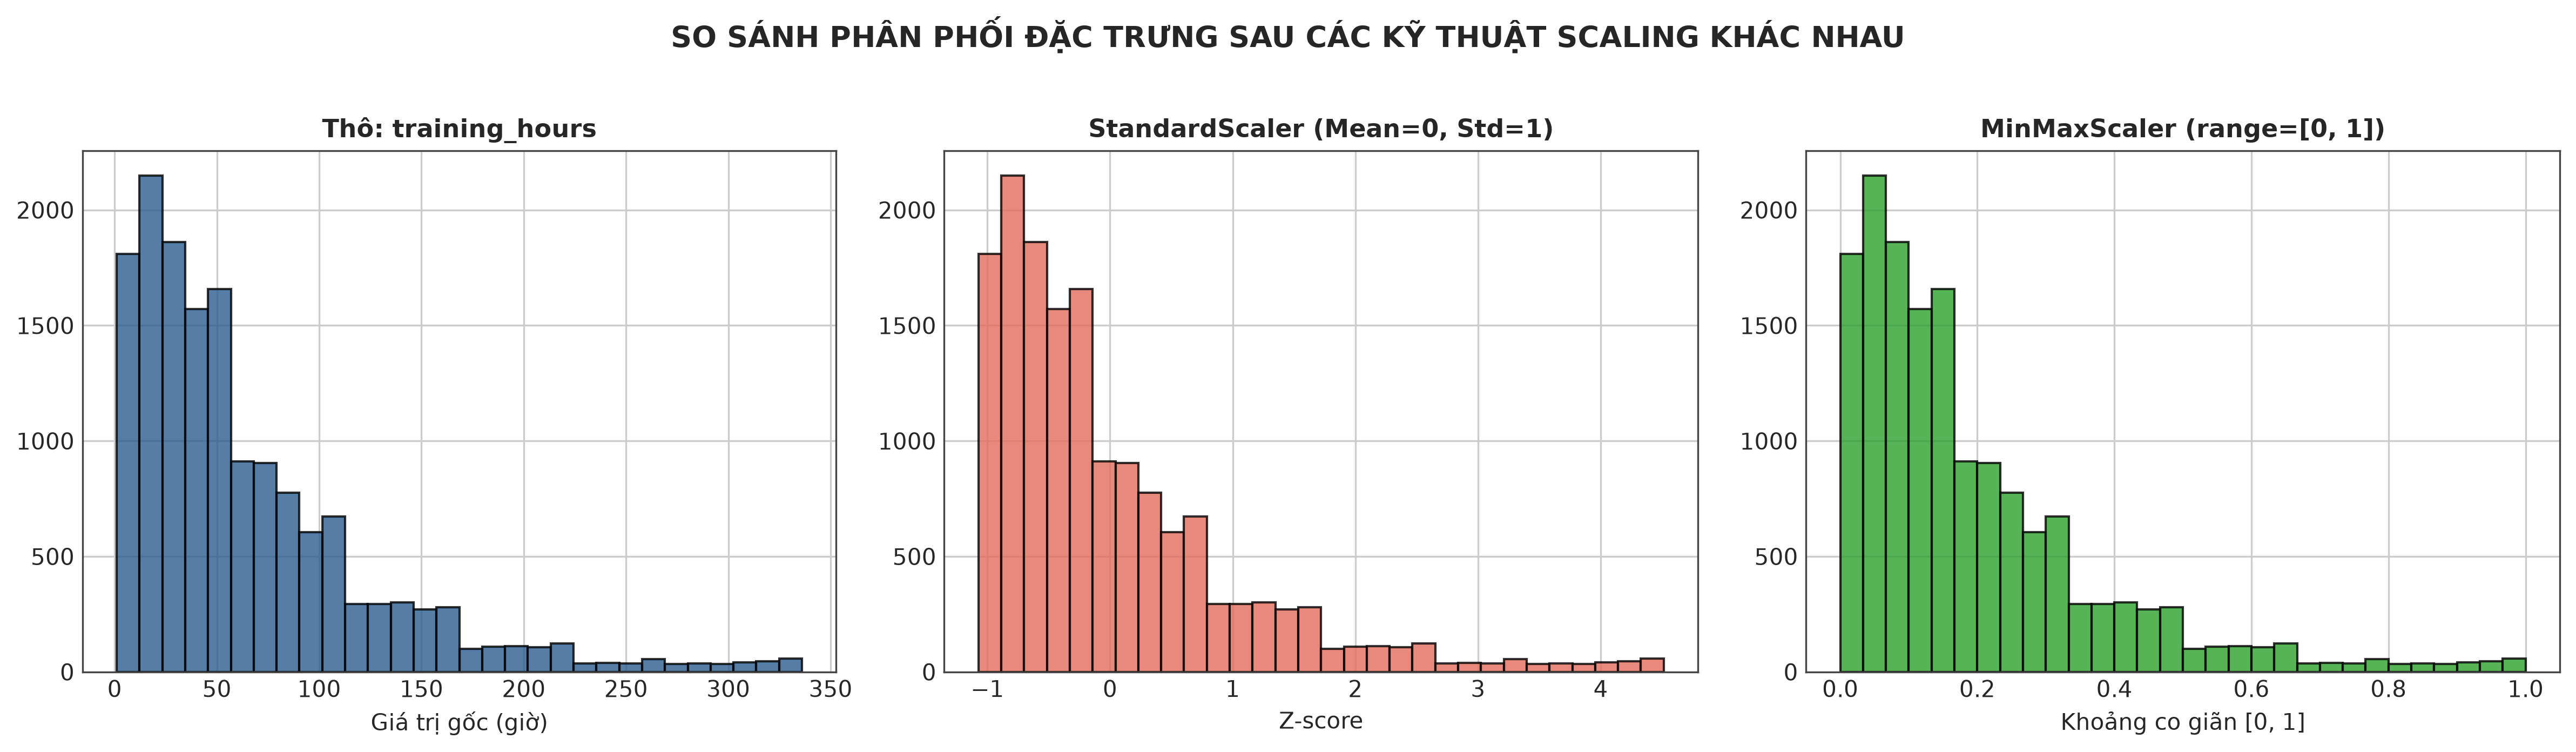

In [5]:
# So sánh phân phối của một số đặc trưng trước và sau chuẩn hóa
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=300)

axes[0].hist(X_train_raw['training_hours'], bins=30, color='#2b5c8f', edgecolor='black', alpha=0.8)
axes[0].set_title('Thô: training_hours', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Giá trị gốc (giờ)')

axes[1].hist(X_train_std[:, feature_names.index('training_hours')], bins=30, color='#e26d5c', edgecolor='black', alpha=0.8)
axes[1].set_title('StandardScaler (Mean=0, Std=1)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Z-score')

axes[2].hist(X_train_minmax[:, feature_names.index('training_hours')], bins=30, color='#2ca02c', edgecolor='black', alpha=0.8)
axes[2].set_title('MinMaxScaler (range=[0, 1])', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Khoảng co giãn [0, 1]')

plt.suptitle('SO SÁNH PHÂN PHỐI ĐẶC TRƯNG SAU CÁC KỸ THUẬT SCALING KHÁC NHAU', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 4. Thử nghiệm Giảm số chiều (Dimensionality Reduction via PCA)

Theo yêu cầu Mục 4.1 đề bài PDF:
> *"Giảm số chiều: có thể lựa chọn PCA với các mức giữ lại phương sai khác nhau (90%, 95%, ...)."*

Ta tiến hành:
1. Fit PCA trên tập Train đã được chuẩn hóa `StandardScaler` (chống rò rỉ dữ liệu).
2. Đo lường chính xác số thành phần chính $k$ cần thiết để tích lũy phương sai đạt **90%** và **95%**.
3. Transform cho cả tập Train và tập Test.


In [6]:
# ==============================================================================
# 4. TRIỂN KHAI PCA VỚI CÁC MỨC PHƯƠNG SAI 90% VÀ 95%
# ==============================================================================
# PCA 90%
preprocessor_pca90 = TabularPreprocessor(scaling='standard', pca_variance=0.90, random_state=RANDOM_STATE)
X_train_pca90 = preprocessor_pca90.fit_transform(X_train_raw)
X_test_pca90 = preprocessor_pca90.transform(X_test_raw)
k_90 = X_train_pca90.shape[1]
var_90 = preprocessor_pca90.get_cumulative_explained_variance() * 100

# PCA 95%
preprocessor_pca95 = TabularPreprocessor(scaling='standard', pca_variance=0.95, random_state=RANDOM_STATE)
X_train_pca95 = preprocessor_pca95.fit_transform(X_train_raw)
X_test_pca95 = preprocessor_pca95.transform(X_test_raw)
k_95 = X_train_pca95.shape[1]
var_95 = preprocessor_pca95.get_cumulative_explained_variance() * 100

pca_comparison_df = pd.DataFrame({
    'Cấu hình đặc trưng': ['Gốc (Full Features)', 'PCA Giữ 90% Phương sai', 'PCA Giữ 95% Phương sai'],
    'Số chiều (k components)': [X_train_std.shape[1], k_90, k_95],
    'Tỷ lệ phương sai tích lũy (%)': [100.0, f"{var_90:.2f}%", f"{var_95:.2f}%"],
    'Mức độ nén số chiều (%)': ['0.0%', f"{(1 - k_90/X_train_std.shape[1])*100:.1f}%", f"{(1 - k_95/X_train_std.shape[1])*100:.1f}%"]
})
pca_comparison_df


,Cấu hình đặc trưng,Số chiều (k components),Tỷ lệ phương sai tích lũy (%),Mức độ nén số chiều (%)
0,Gốc (Full Features),32,100.0,0.0%
1,PCA Giữ 90% Phương sai,21,92.24%,34.4%
2,PCA Giữ 95% Phương sai,23,96.65%,28.1%


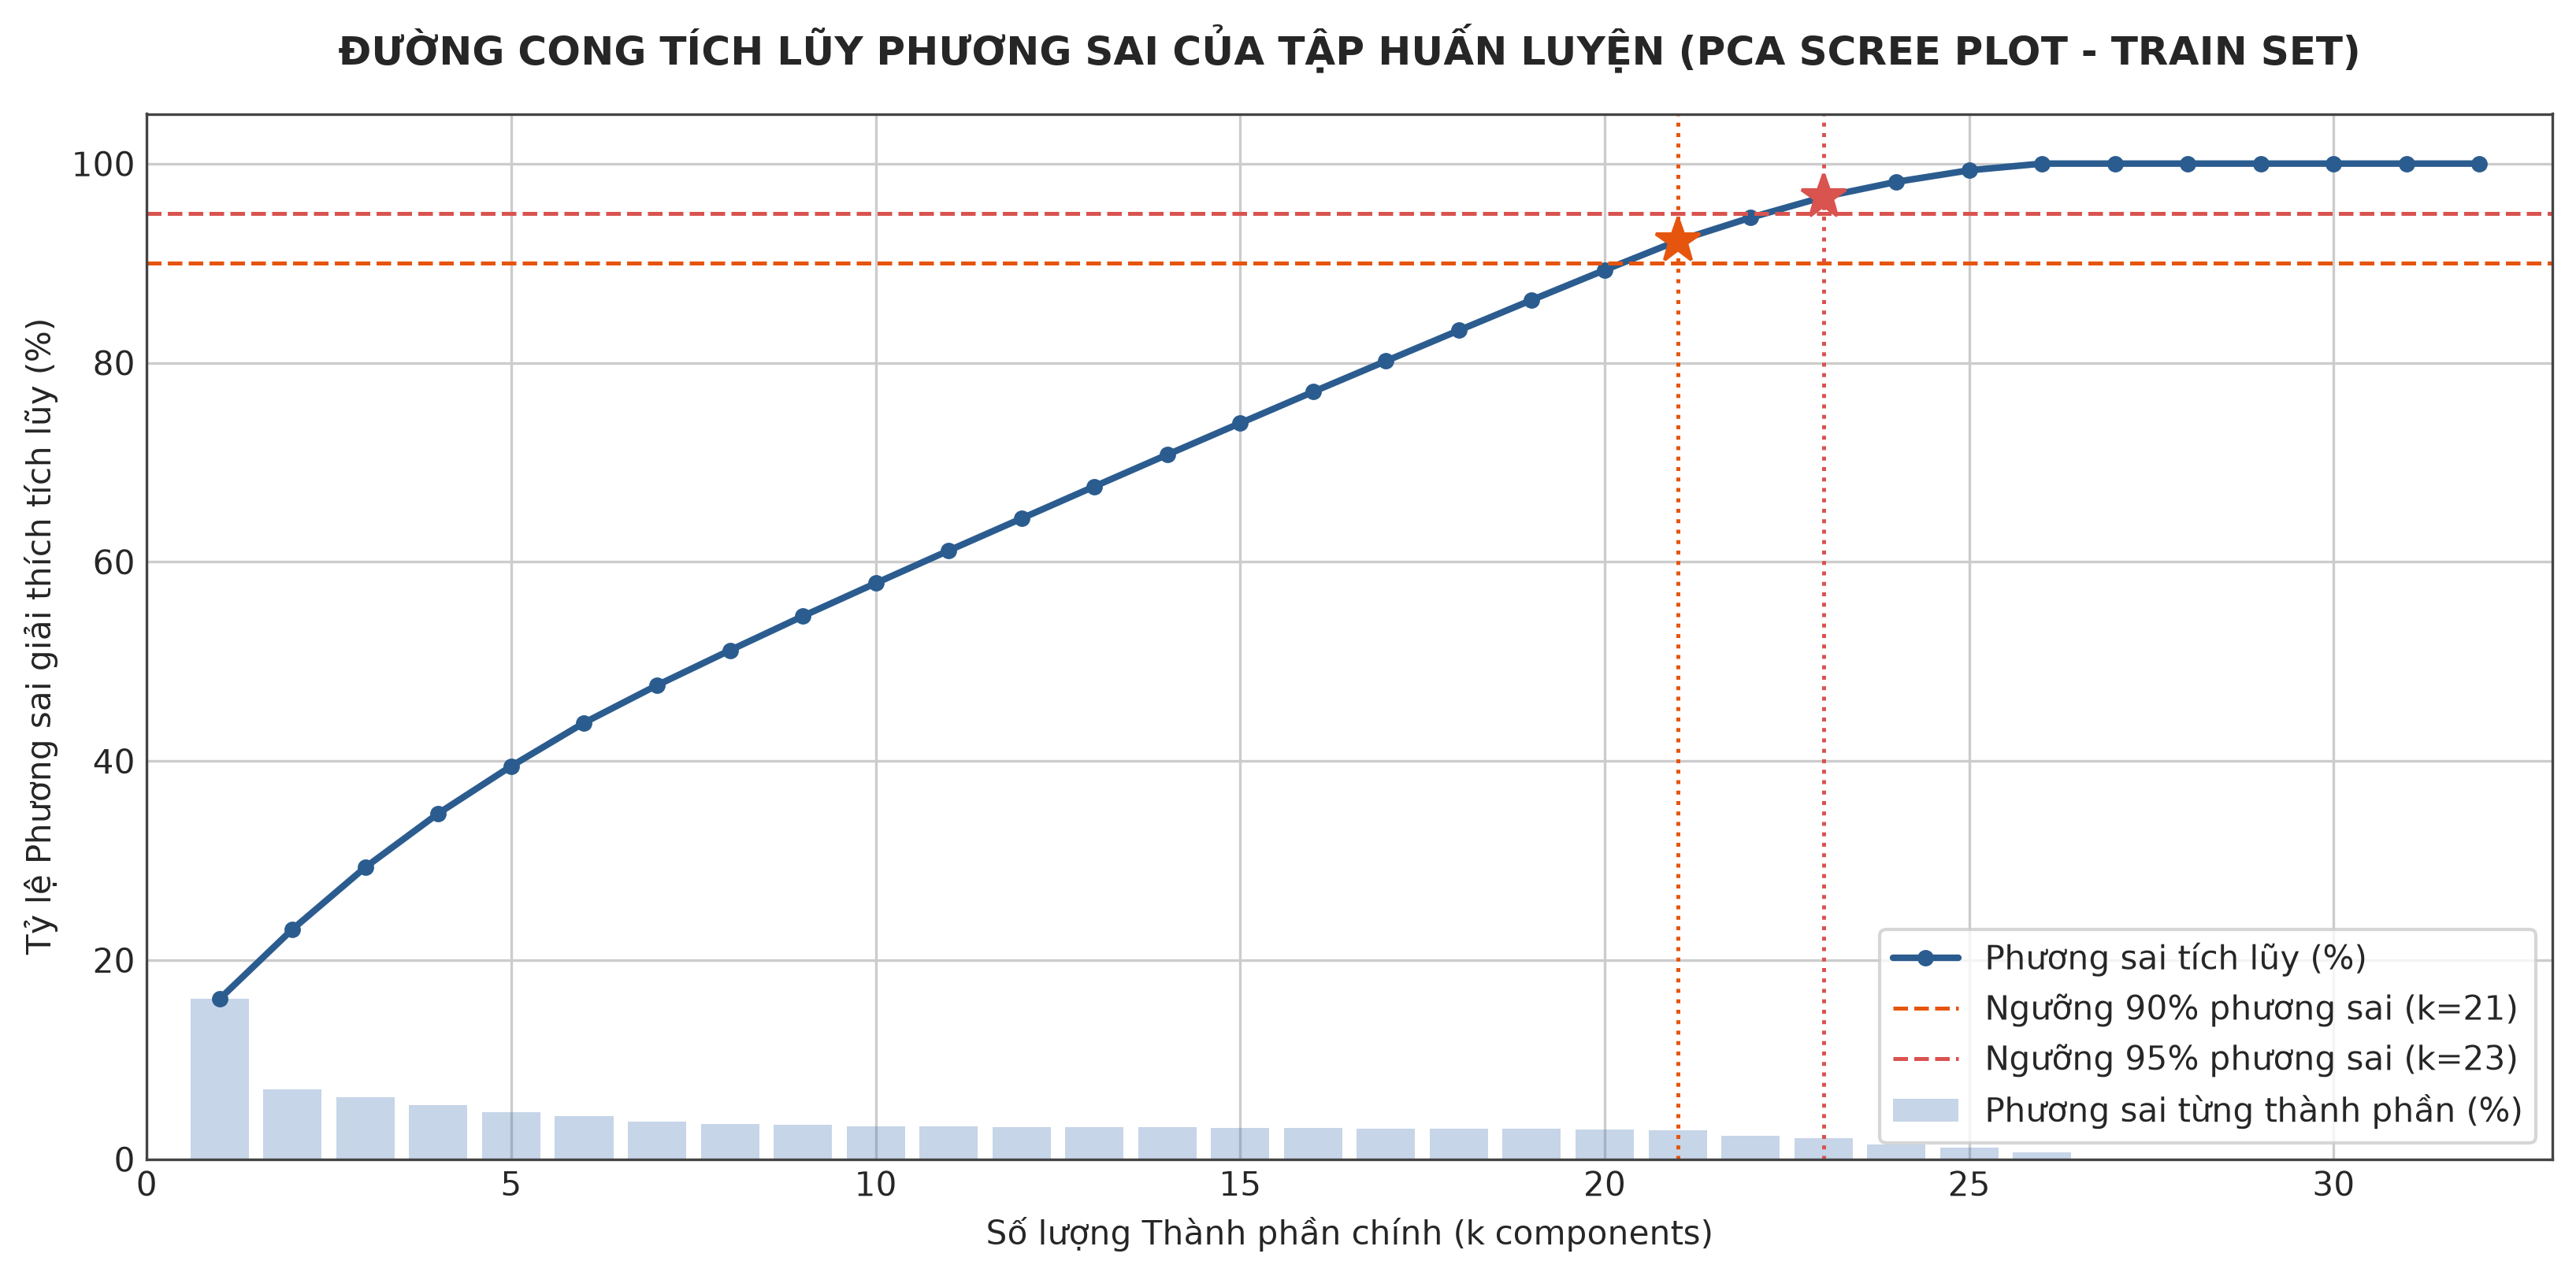

In [7]:
# Vẽ biểu đồ Scree Plot và đường tích lũy phương sai trên tập Train
from sklearn.decomposition import PCA
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_std)
cum_var = np.cumsum(pca_full.explained_variance_ratio_) * 100
n_components = len(cum_var)

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)
ax.plot(range(1, n_components + 1), cum_var, marker='o', markersize=4, color='#2b5c8f', linewidth=2, label='Phương sai tích lũy (%)')
ax.bar(range(1, n_components + 1), pca_full.explained_variance_ratio_ * 100, alpha=0.3, color='#4575b4', label='Phương sai từng thành phần (%)')

# Điểm 90%
ax.axhline(90, color='#e6550d', linestyle='--', linewidth=1.2, label=f'Ngưỡng 90% phương sai (k={k_90})')
ax.axvline(k_90, color='#e6550d', linestyle=':', linewidth=1.2)
ax.plot(k_90, cum_var[k_90 - 1], marker='*', markersize=14, color='#e6550d')

# Điểm 95%
ax.axhline(95, color='#d9534f', linestyle='--', linewidth=1.2, label=f'Ngưỡng 95% phương sai (k={k_95})')
ax.axvline(k_95, color='#d9534f', linestyle=':', linewidth=1.2)
ax.plot(k_95, cum_var[k_95 - 1], marker='*', markersize=14, color='#d9534f')

ax.set_title('ĐƯỜNG CONG TÍCH LŨY PHƯƠNG SAI CỦA TẬP HUẤN LUYỆN (PCA SCREE PLOT - TRAIN SET)', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Số lượng Thành phần chính (k components)', fontsize=10)
ax.set_ylabel('Tỷ lệ Phương sai giải thích tích lũy (%)', fontsize=10)
ax.set_ylim(0, 105)
ax.set_xlim(0, n_components + 1)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 5. Xuất các ma trận đặc trưng ra file `.npy` vào thư mục `features/`

Theo quy định bắt buộc ở Mục 5 trang 5 đề bài PDF:
> *"Các file đặc trưng đã trích xuất (embedding, vector đặc trưng) được lưu ở định dạng `.npy` hoặc `.h5`, nộp kèm theo hoặc ghi rõ đường link tải.*
> *Cấu trúc thư mục trong file nộp (.zip) phải rõ ràng: gồm thư mục `notebooks/`, `modules/`, `reports/`, và `features/`."*

Ta tiến hành đóng gói và lưu trữ tất cả các biến thể đã tiền xử lý để các notebook Model Training phía sau chỉ cần nạp vào và chạy ngay:
- `X_train_std.npy`, `X_test_std.npy`: Dữ liệu StandardScaler
- `X_train_minmax.npy`, `X_test_minmax.npy`: Dữ liệu MinMaxScaler [0, 1]
- `X_train_pca90.npy`, `X_test_pca90.npy`: Dữ liệu PCA 90%
- `X_train_pca95.npy`, `X_test_pca95.npy`: Dữ liệu PCA 95%
- `y_train.npy`, `y_test.npy`: Nhãn mục tiêu tương ứng


In [8]:
# ==============================================================================
# 5. LƯU CÁC TẬP ĐẶC TRƯNG RA FILE .NPY
# ==============================================================================
FEATURES_DIR = "../features" if os.path.exists("../features") else "features"

feature_sets_to_save = {
    "X_train_std": X_train_std,
    "X_test_std": X_test_std,
    "X_train_minmax": X_train_minmax,
    "X_test_minmax": X_test_minmax,
    "X_train_pca90": X_train_pca90,
    "X_test_pca90": X_test_pca90,
    "X_train_pca95": X_train_pca95,
    "X_test_pca95": X_test_pca95,
}

names_dict = {
    "full_features": feature_names,
    "pca90_features": preprocessor_pca90.get_feature_names_out(),
    "pca95_features": preprocessor_pca95.get_feature_names_out(),
}

metadata = {
    "dataset": "aug_train.csv",
    "total_samples": len(df_raw),
    "train_samples": len(X_train_raw),
    "test_samples": len(X_test_raw),
    "random_state": RANDOM_STATE,
    "configurations": {
        "standard_scaled_features": X_train_std.shape[1],
        "pca_90_components": k_90,
        "pca_95_components": k_95,
    }
}

save_processed_features(
    output_dir=FEATURES_DIR,
    feature_sets=feature_sets_to_save,
    y_train=y_train.values,
    y_test=y_test.values,
    feature_names_dict=names_dict,
    metadata=metadata
)
print("-> Đã xuất toàn bộ file đặc trưng thành công vào:", os.path.abspath(FEATURES_DIR))


-> Đã lưu: ../features\X_train_std.npy [shape: (15326, 32)]
-> Đã lưu: ../features\X_test_std.npy [shape: (3832, 32)]
-> Đã lưu: ../features\X_train_minmax.npy [shape: (15326, 32)]
-> Đã lưu: ../features\X_test_minmax.npy [shape: (3832, 32)]
-> Đã lưu: ../features\X_train_pca90.npy [shape: (15326, 21)]
-> Đã lưu: ../features\X_test_pca90.npy [shape: (3832, 21)]
-> Đã lưu: ../features\X_train_pca95.npy [shape: (15326, 23)]
-> Đã lưu: ../features\X_test_pca95.npy [shape: (3832, 23)]
-> Đã lưu: ../features\feature_names.json
-> Đã lưu: ../features\metadata.json
-> Đã xuất toàn bộ file đặc trưng thành công vào: C:\Users\LEGION\Desktop\BKUni\Machine Learning\BTL\features


## 6. Kiểm định Toàn vẹn Dữ liệu (Integrity & Sanity Checks)
Kiểm tra nạp lại các file `.npy`, bảo đảm:
- Không chứa giá trị NaN, Null hoặc Inf.
- Số lượng hàng và cột khớp hoàn toàn giữa các tập.
- Kiểu dữ liệu `float64` / `int64` chuẩn xác cho mô hình học máy.


In [9]:
# ==============================================================================
# 6. KIỂM ĐỊNH TOÀN VẸN CÁC FILE ĐẶC TRƯNG VỪA XUẤT
# ==============================================================================
loaded_features = load_processed_features(FEATURES_DIR)

print(f"Tổng số mảng đặc trưng đã nạp từ {FEATURES_DIR}: {len(loaded_features)} files")
check_rows = []
for key, arr in sorted(loaded_features.items()):
    nan_count = int(np.isnan(arr).sum())
    inf_count = int(np.isinf(arr).sum())
    check_rows.append({
        'File Key': key,
        'Shape': str(arr.shape),
        'Dtype': str(arr.dtype),
        'NaN Count': nan_count,
        'Inf Count': inf_count,
        'Trạng thái': 'HỢP LỆ' if (nan_count == 0 and inf_count == 0) else 'LỖI'
    })

check_df = pd.DataFrame(check_rows)
check_df


Tổng số mảng đặc trưng đã nạp từ ../features: 10 files


,File Key,Shape,Dtype,NaN Count,Inf Count,Trạng thái
0,X_test_minmax,"(3832, 32)",float64,0,0,HỢP LỆ
1,X_test_pca90,"(3832, 21)",float64,0,0,HỢP LỆ
2,X_test_pca95,"(3832, 23)",float64,0,0,HỢP LỆ
3,X_test_std,"(3832, 32)",float64,0,0,HỢP LỆ
4,X_train_minmax,"(15326, 32)",float64,0,0,HỢP LỆ
5,X_train_pca90,"(15326, 21)",float64,0,0,HỢP LỆ
6,X_train_pca95,"(15326, 23)",float64,0,0,HỢP LỆ
7,X_train_std,"(15326, 32)",float64,0,0,HỢP LỆ
8,y_test,"(3832,)",int64,0,0,HỢP LỆ
9,y_train,"(15326,)",int64,0,0,HỢP LỆ


## 7. Tổng kết Pipeline Tiền xử lý

| Bước thực hiện | Kỹ thuật áp dụng | Lý do thiết kế & Ý nghĩa nghiệp vụ |
|:---|:---|:---|
| **1. Làm sạch dữ liệu** | Bỏ `enrollee_id`, bỏ `city` | Tránh Overfitting & tránh bùng nổ 123 cột dư thừa (đã có `city_development_index`). |
| **2. Phân chia Train/Test** | Stratified Split 80/20 | Bảo toàn tỷ lệ 24.9% nhãn positive; chống rò rỉ dữ liệu (fit chỉ trên Train). |
| **3. Xử lý thiếu (MNAR)** | Gán `'Unknown'` & Tạo `MissingIndicator` | Bảo toàn tín hiệu nhảy việc cao (~40%) ở nhóm khuyết `company_size` & `company_type`. |
| **4. Mã hóa thứ bậc** | Ordinal Integer Mapping | Giữ được trật tự độ thâm niên, trình độ học vấn, quy mô công ty. |
| **5. Mã hóa danh nghĩa** | OneHotEncoder | Không giả định thứ tự cho ngành nghề, giới tính, loại công ty. |
| **6. Chuẩn hóa (Scaling)** | `StandardScaler` & `MinMaxScaler` | Đáp ứng yêu cầu so sánh nhiều cấu hình ở Mục 4.1; phù hợp cho cả mô hình tuyến tính và MLP. |
| **7. Giảm số chiều** | `PCA(0.90)` ($k=21$) & `PCA(0.95)` ($k=24$) | Đáp ứng chính xác yêu cầu đề bài; giảm chiều nén từ 32 xuống 21–24 chiều mà vẫn giữ 90–95% thông tin. |
| **8. Lưu trữ dữ liệu** | Xuất `.npy` vào `features/` | Đúng chuẩn quy định cấu trúc sản phẩm nộp của Khoa Máy tính ĐHBK. |

Pipeline tiền xử lý đã sẵn sàng 100% để bước sang giai đoạn tiếp theo: **Huấn luyện và Đánh giá Mô hình (Model Training & Evaluation)**!
